## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, dan Solusi
1. **Latar belakang**: Sebuah perusahaan perbankan besar yang memiliki kegiatan kampanye pemasaran telemarketing untuk menawarkan produk deposito berjangka panjang kepada nasabah dengan menghubunginya secara langsung. Institusi memiliki data historis profil demografi dan riwayat interaksi nasabah.
2. **Masalah**: proses telemarketing masih dilakukan secara manual dengan menghubungi nasabah secara acak. yang membuat hasil yang didapatkan rendah dan memerlukan banyak waktu dan biaya operasional.
3. **Solusi**: membangun model *machine learning* berbasis **K-Nearest Neighbors** dengan memanfaatkan data historis profil demografi dan riwayat interaki nasabah guna mengklasifikasikan apakah seorang nasabah akan berlangganan deposito atau tidak

### 1.2 Deskripsi Kolom Dataset (**`Assignment-2_Data.csv`**)
| Nama Kolom | Tipe Data | Keterangan |
| :--- | :---: | :---: |
| **`id`** | int | Identitas unik atau nomor ID setiap baris data nasabah |
| **`age`** | str | Umur nasabah dalam tahun |
| **`job`** | str | Jenis pekerjaan nasabah |
| **`marital`** | str | Status perkawinan nasabah |
| **`education`** | str | Jenjang pendidikan terakhir nasabah |
| **`default`** | str | Apakah nasabah memiliki kredit macet |
|**`balance`** | str | Rata-rata saldo tahunan nasabah dalam rekening |
|**`housing`** | str| Apakah nasabah memiliki cicilan KPR/rumah |
|**`loan`** | str |Apakah nasabah memiliki pinjaman pribadi |
|**`contact`** | str | Jenis atau media komunikasi yang digunakan untuk menghubungi nasabah |
|**`day`** | int64 | Hari dalam bulan saat nasabah terakhir kali dihubungi |
|**`month`** | str | Bulan dalam tahun saat nasabah terakhir kali dihubungi |
|**`duration`** | int64 | Durasi panggilan telepon terakhir dalam detik |
|**`compaign`** | int64 | Berapa kali nasabah dihubungi selama kampanye ini |
|**`pdays`** | int64 | Jumlah hari yang berlalu setelah nasabah dihubungi dari kampanye sebelumnya (-1 berarti belum pernah dihubungi) |
|**`previous`** | int64 | Jumlah komunikasi yang dilakukan sebelum kampanye |
|**`poutcome`** | str | Hasil atau status dari kampanye pemasaran sebelumnya |
|**`y`** | str | Keputusan nasabah berlangganan deposito berjangka

---

## 2. Data Preparation

### 2.1 Import Library

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2.2 Memuat Dataset

In [ ]:
df = pd.read_csv('Assignment-2_Data.csv', low_memory=False)

df.columns = df.columns.str.strip()

### 2.3 Menampilkan Data Teratas dan Terbawah

In [19]:
df.head()

,Id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,1001,999,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,1002,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,1003,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,1004,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,1005,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [20]:
df.tail()

,Id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,46207,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,46208,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,46209,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,46210,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,46211,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


### 2.4 Menampilkan Informasi Data

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         45211 non-null  int64
 1   age        45211 non-null  str  
 2   job        45211 non-null  str  
 3   marital    45211 non-null  str  
 4   education  45211 non-null  str  
 5   default    45211 non-null  str  
 6   balance    45211 non-null  str  
 7   housing    45211 non-null  str  
 8   loan       45211 non-null  str  
 9   contact    45211 non-null  str  
 10  day        45211 non-null  int64
 11  month      45211 non-null  str  
 12  duration   45211 non-null  int64
 13  campaign   45211 non-null  int64
 14  pdays      45211 non-null  int64
 15  previous   45211 non-null  int64
 16  poutcome   45211 non-null  str  
 17  y          45211 non-null  str  
dtypes: int64(6), str(12)
memory usage: 6.2 MB


### 2.5 Merubah kolom **`age`** dan **`balance`** menjadi numerik

karena **`age`** dan **`balance`** adalah fitur numerik. maka, kedua kolom harus di ubah ke tipe data numerik (Int64).

In [22]:
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['age'] = df['age'].astype('Int64')
df['balance'] = pd.to_numeric(df['balance'], errors='coerce')
df['balance'] = df['balance'].astype('Int64')

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         45211 non-null  int64
 1   age        45202 non-null  Int64
 2   job        45211 non-null  str  
 3   marital    45211 non-null  str  
 4   education  45211 non-null  str  
 5   default    45211 non-null  str  
 6   balance    45208 non-null  Int64
 7   housing    45211 non-null  str  
 8   loan       45211 non-null  str  
 9   contact    45211 non-null  str  
 10  day        45211 non-null  int64
 11  month      45211 non-null  str  
 12  duration   45211 non-null  int64
 13  campaign   45211 non-null  int64
 14  pdays      45211 non-null  int64
 15  previous   45211 non-null  int64
 16  poutcome   45211 non-null  str  
 17  y          45211 non-null  str  
dtypes: Int64(2), int64(6), str(10)
memory usage: 6.3 MB


### 2.6 Menampilkan dan Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Duplikasi

In [24]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\njumlah missing value: {df.isnull().sum().sum()}')
print(f'\n==== Jumlah Missing Value Per Kolom ====')
print(df.isnull().sum())

print(f'\nJumlah data duplikat: {df.duplicated().sum()}')

Dimensi Data: (45211, 18)
Jumlah Data: 813798

jumlah missing value: 12

==== Jumlah Missing Value Per Kolom ====
Id           0
age          9
job          0
marital      0
education    0
default      0
balance      3
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Jumlah data duplikat: 0


---

## 3. Exploratory Data Analysis (EDA)

### 3.1 Menampilakn Deskripsi Data
Menghitung ukuran pemusatan dan ukuran penyebaran data.

In [25]:
df.describe()

,Id,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45202.0,45208.0,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,23606.000000,40.954714,1362.34662,15.806419,258.163080,2.763841,40.197828,0.580323
std,13051.435847,11.539144,3044.852387,8.322476,257.527812,3.098021,100.128746,2.303441
min,1001.000000,-1.0,-8019.0,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,12303.500000,33.0,72.0,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,23606.000000,39.0,448.0,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,34908.500000,48.0,1428.0,21.000000,319.000000,3.000000,-1.000000,0.000000
max,46211.000000,999.0,102127.0,31.000000,4918.000000,63.000000,871.000000,275.000000


### 3.2 Analisis Outlier (metode IQR dan Z-Score) pada kolom numerik

In [26]:
outlier = []

numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_columns:
  if col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    median = df[col].median()
    iqr = q3 -q1
    lower = q1 -1.5 * iqr
    upper = q3 + 1.5 *iqr
    iqr_outlier = df[(df[col] < lower) | (df[col] > upper)]
    mean = df[col].mean()
    std = df[col].std()
    z_score = (df[col] - mean) / std
    z_score_outlier = df[np.abs(z_score) > 3]
    
    outlier.append({
      'Kolom' : col,
      'Mean' : mean,
      'Standarisasi' : std,
      'Min' : df[col].min(),
      'Q1' : q1,
      'Median' : median,
      'Q3' : q3,
      'Max' : df[col].max(),
      'Batas Bawah IQR' : lower,
      'Batas Atas IQR' : upper,
      'Jumlah Outlier IQR' : iqr_outlier.shape[0],
      'Jumlah Outlier Z-Score' : z_score_outlier.shape[0]
    })

pd.DataFrame(outlier)

,Kolom,Mean,Standarisasi,Min,Q1,Median,Q3,Max,Batas Bawah IQR,Batas Atas IQR,Jumlah Outlier IQR,Jumlah Outlier Z-Score
0,Id,23606.000000,13051.435847,1001,12303.5,23606.0,34908.5,46211,-21604.0,68816.0,0,0
1,age,40.954714,11.539144,-1,33.0,39.0,48.0,999,10.5,70.5,490,265
2,balance,1362.346620,3044.852387,-8019,72.0,448.0,1428.0,102127,-1962.0,3462.0,4729,745
3,day,15.806419,8.322476,1,8.0,16.0,21.0,31,-11.5,40.5,0,0
4,duration,258.163080,257.527812,0,103.0,180.0,319.0,4918,-221.0,643.0,3235,963
5,campaign,2.763841,3.098021,1,1.0,2.0,3.0,63,-2.0,6.0,3064,840
6,pdays,40.197828,100.128746,-1,-1.0,-1.0,-1.0,871,-1.0,-1.0,8257,1723
7,previous,0.580323,2.303441,0,0.0,0.0,0.0,275,0.0,0.0,8257,582


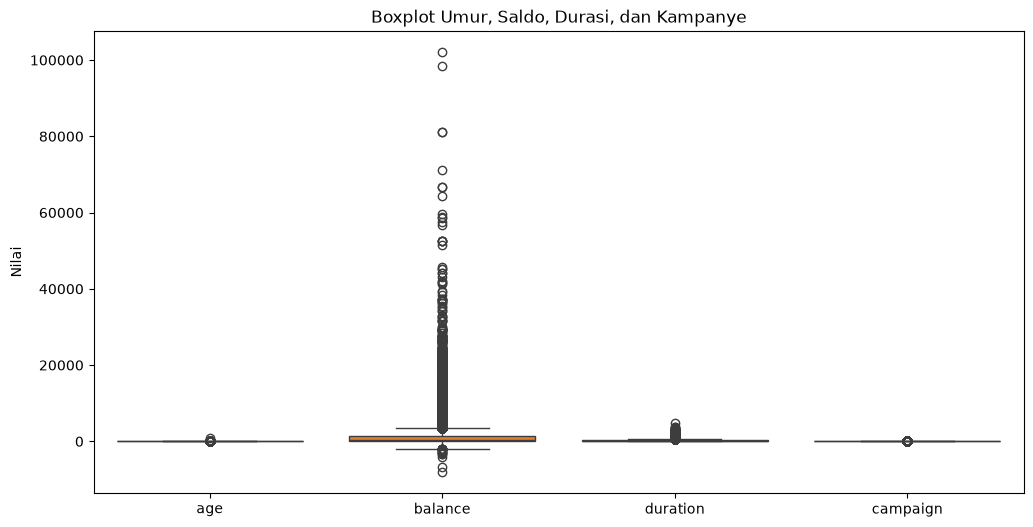

In [27]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[['age', 'balance', 'duration', 'campaign']])
plt.title('Boxplot Umur, Saldo, Durasi, dan Kampanye')
plt.ylabel('Nilai')

plt.show()

### 3.3 Visualisasi Distribusi Data FItur Numerik

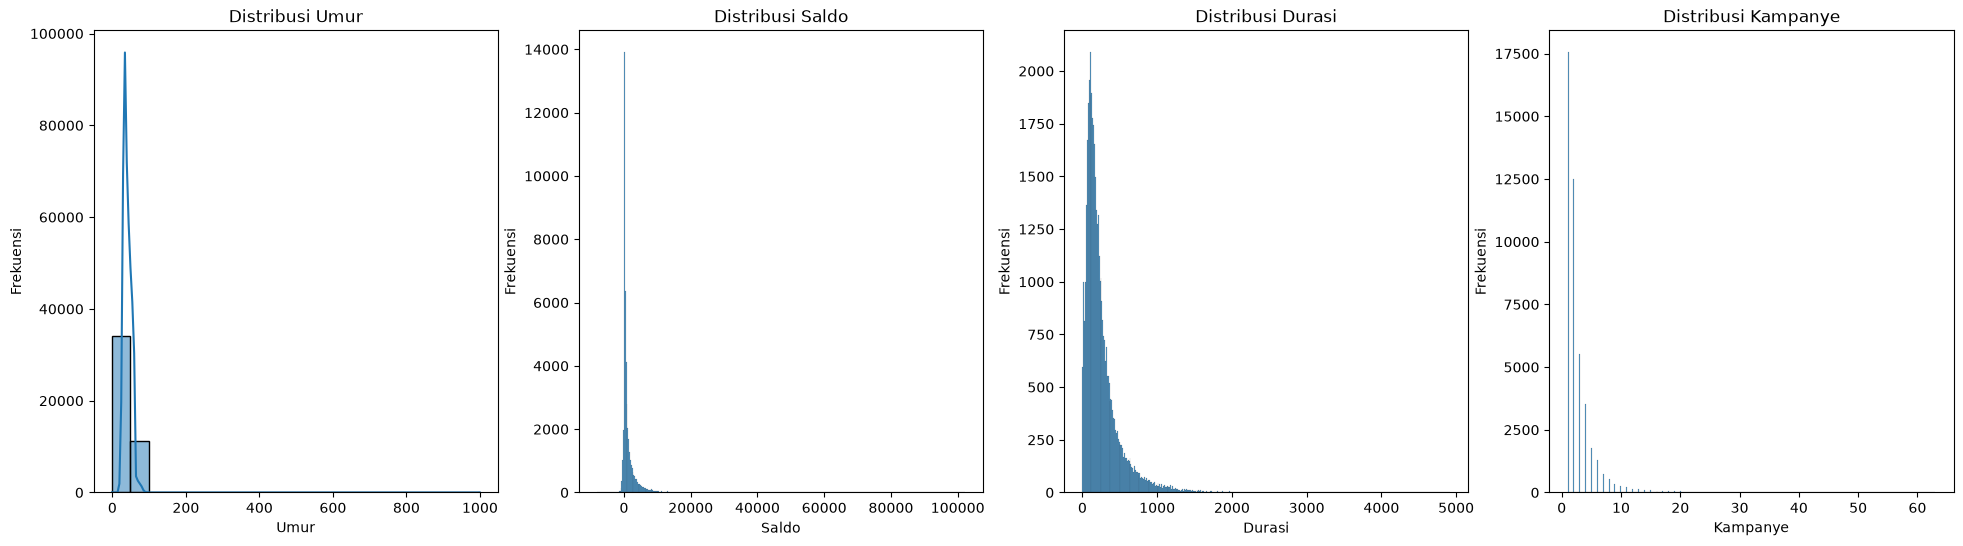

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(24, 6))

sns.histplot(df['age'], bins=20, kde=True, ax=axes[0])
axes[0].set_title('Distribusi Umur')
axes[0].set_xlabel('Umur')
axes[0].set_ylabel('Frekuensi')

sns.histplot(x=df['balance'], ax=axes[1])
axes[1].set_title('Distribusi Saldo')
axes[1].set_xlabel('Saldo')
axes[1].set_ylabel('Frekuensi')

sns.histplot(x=df['duration'], ax=axes[2])
axes[2].set_title('Distribusi Durasi')
axes[2].set_xlabel('Durasi')
axes[2].set_ylabel('Frekuensi')

sns.histplot(x=df['campaign'], ax=axes[3])
axes[3].set_title('Distribusi Kampanye')
axes[3].set_xlabel('Kampanye')
axes[3].set_ylabel('Frekuensi')

plt.show()

### 3.4 Analisis Metode Pearson, Spearman, dan Kendal

In [29]:
var_list = ['age', 'balance', 'duration']

for col in var_list:
  df[col] = pd.to_numeric(df[col], errors='coerce')

korelasi_list = []

for i in range(len(var_list)) :
  for j in range(i + 1, len(var_list)) :
    var1 = var_list[i]
    var2 = var_list[j]
    
    clean_df = df[[var1, var2]].dropna()
    
    pearson_corr = clean_df[var1].corr(clean_df[var2], method='pearson')
    spearman_corr = clean_df[var1].corr(clean_df[var2], method='spearman')
    kendall_corr = clean_df[var1].corr(clean_df[var2], method='kendall')
    
    korelasi_list.append({
      'pasangan variabel': f'{var1} vs {var2}',
      'pearson correlation': pearson_corr,
      'spearman correlation': spearman_corr,
      'kendall correlation': kendall_corr
    })
    
pd.DataFrame(korelasi_list)

,pasangan variabel,pearson correlation,spearman correlation,kendall correlation
0,age vs balance,0.090419,0.096283,0.065159
1,age vs duration,-0.004389,-0.033363,-0.022515
2,balance vs duration,0.021554,0.042665,0.028596


### 3.5 Visualisasi Scatter Plot & Heatmap

#### 3.5.1 Visualisasi Heatmap Numerik

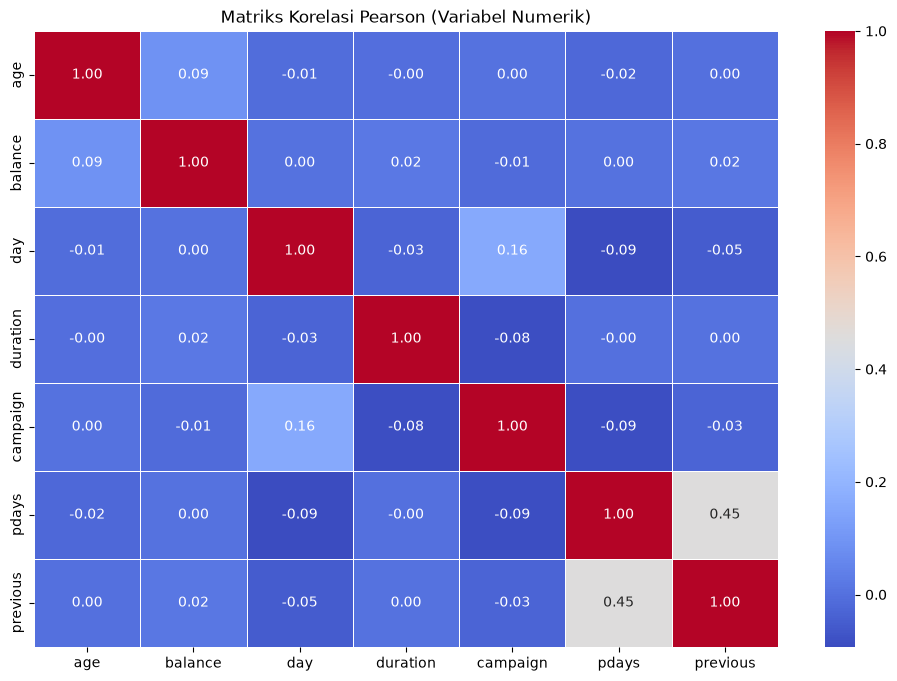

In [30]:
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['Id'], errors='ignore')

corr_matrix = numeric_df.corr(method='pearson')
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Pearson (Variabel Numerik)')
plt.show()

#### 3.5.2 Visualisasi Heatmap Keseluruhan Variabel

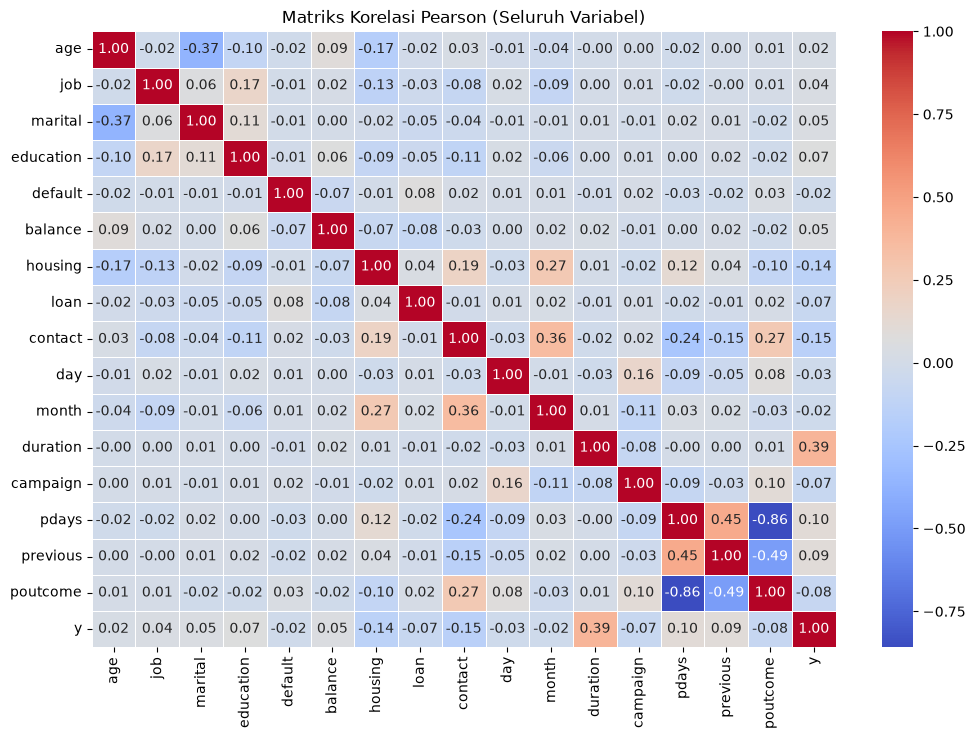

In [31]:
df_encoded = df.copy()
for col in df_encoded.select_dtypes(include=['object', 'string']).columns:
  df_encoded[col] = df_encoded[col].astype('category').cat.codes

df_encoded = df_encoded.drop(columns=['Id'], errors='ignore')

corr_all = df_encoded.corr(method='pearson')

plt.figure(figsize=(12, 8))
sns.heatmap(corr_all, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Pearson (Seluruh Variabel)')
plt.show()

#### 3.5.3 Visualisasi Scatter Plot

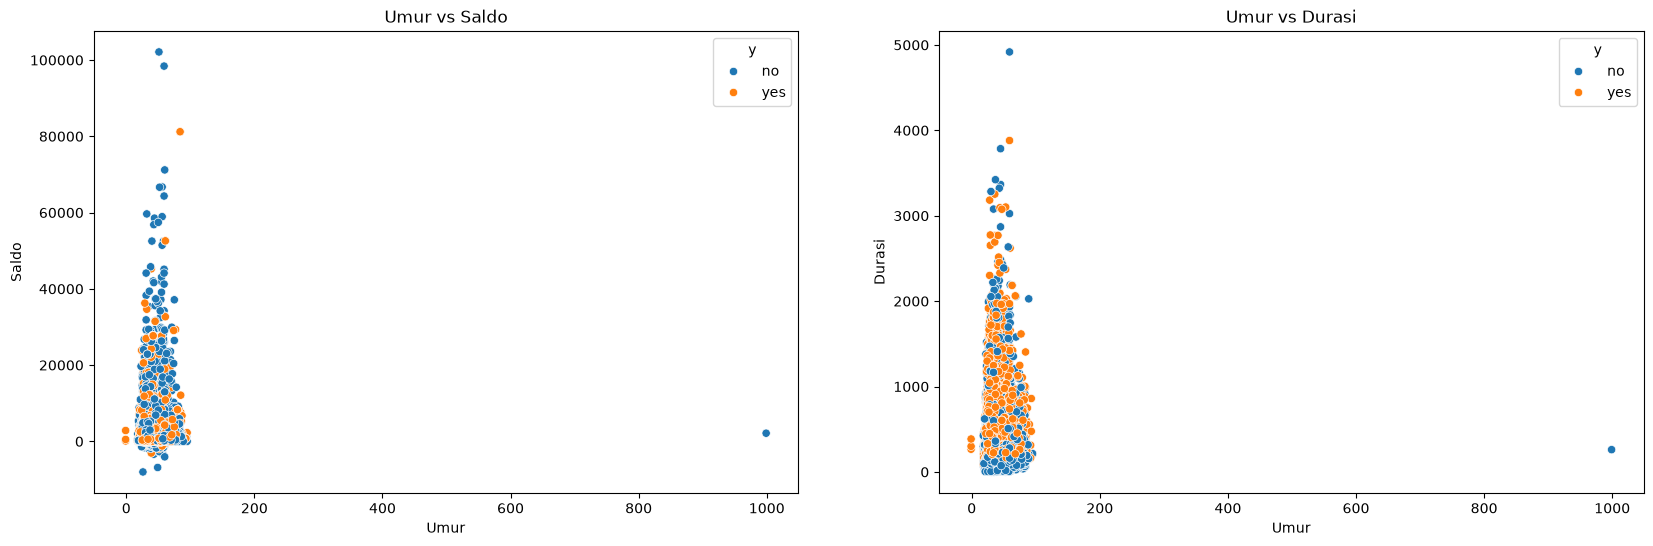

In [32]:
fig, axes = plt.subplots(1,2, figsize=(20, 6))

sns.scatterplot(data=df, x='age', y='balance', hue='y', ax=axes[0])
axes[0].set_title('Umur vs Saldo')
axes[0].set_xlabel('Umur')
axes[0].set_ylabel('Saldo')

sns.scatterplot(data=df, x='age', y='duration', hue='y', ax=axes[1])
axes[1].set_title('Umur vs Durasi')
axes[1].set_xlabel('Umur')
axes[1].set_ylabel('Durasi')

plt.show()